# Quicksort under the Mallows distribution

An interactive companion to [Fidy-Heritiana/Quicksort-Mallows](https://github.com/Fidy-Heritiana/Quicksort-Mallows).

Run the cells from top to bottom. In Colab, use **Runtime → Run all**.
The first cell retrieves the repository when necessary and installs the notebook dependencies.

We study first-pivot Quicksort with stable partition and a **fixed** Mallows parameter $0<\phi<1$.
The numerical functions are imported directly from the research scripts.
The figures illustrate finite-size behaviour; the limit theorem requires the analytic proof.

In [ ]:
from pathlib import Path
import os
import subprocess
import sys

REPOSITORY_URL = "https://github.com/Fidy-Heritiana/Quicksort-Mallows.git"
if not Path("explore.py").is_file():
    repository = Path.cwd() / "Quicksort-Mallows"
    if not repository.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPOSITORY_URL, str(repository)], check=True)
    if not (repository / "explore.py").is_file():
        raise FileNotFoundError("Open this notebook from the complete Quicksort-Mallows repository.")
    os.chdir(repository)

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-notebook.txt"], check=True)
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
print("Repository and notebook dependencies are ready.")

In [ ]:
import json
import numpy as np
import pandas as pd
import plotly.io as pio
from IPython.display import Image, display
from explore import (
    ROOT, SAVED_PARAMETERS, METRICS, load_manuscript, run_experiment,
    summary_table, sample_table, moment_table, normal_figures,
    convergence_figure, experiment_metadata,
)

try:
    from google.colab import output
except ImportError:
    pio.renderers.default = "notebook_connected"
else:
    output.enable_custom_widget_manager()
    pio.renderers.default = "colab"

print("The original manuscript data are preserved by this notebook.")

## 1. Original manuscript data

The original experiment uses $n=1000$ and 12,000 independent costs for each
$\phi\in\{0.25,0.5,0.8\}$. These are the same saved samples as in the manuscript.
The PNG below is included so that the figure is also visible in GitHub's static preview.

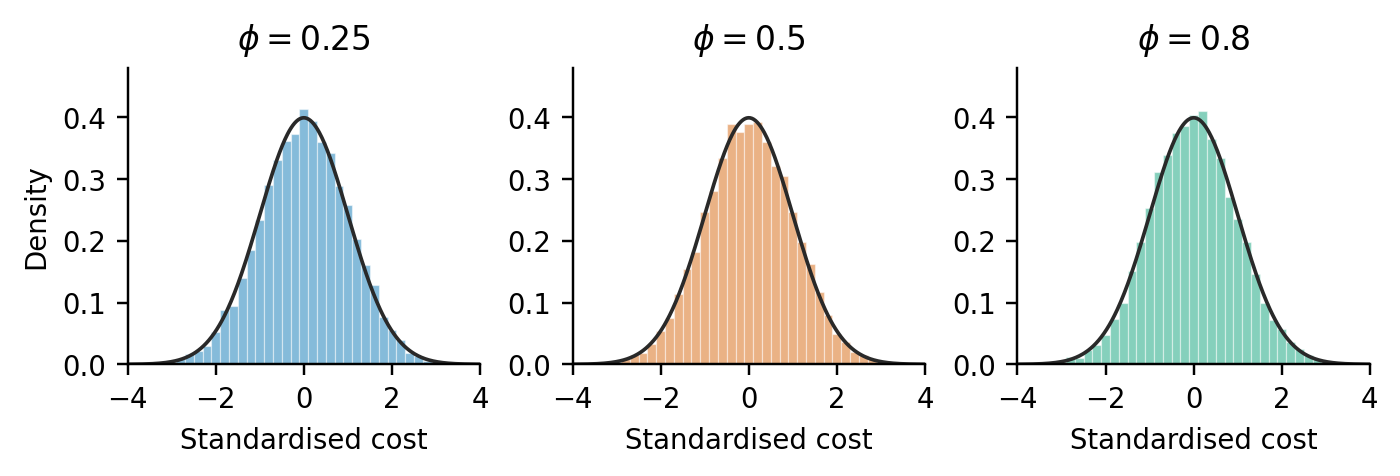

,Quantity,Finite recurrence,Monte Carlo
0,Mean,2.506583e+05,2.507314e+05
1,Variance,8.240595e+07,8.249198e+07


{
  "model": "First-pivot Quicksort with stable partition on Mallows input",
  "phi": 0.5,
  "n": 1000,
  "repetitions": 12000,
  "seed": 20260922,
  "source": "Original manuscript data",
  "finite_mean": 250658.33672051842,
  "finite_variance": 82405951.67764094,
  "max_centred_moment_order": 6,
  "max_relative_centring_residual": 2.2172457452705307e-20,
  "standardisation": "(cost - finite_mean) / sqrt(finite_variance)"
}


In [ ]:
display(Image(filename=str(ROOT / "figures/normal_histograms.png")))
saved = load_manuscript("0.5")
display(summary_table(saved))
print(json.dumps(experiment_metadata(saved), indent=2))

## 2. Explore a saved experiment

Choose a parameter and press **Show saved experiment**. Hover over or zoom into the plots.
Normalisation uses the finite theoretical mean and variance, not the empirical estimates.

In [ ]:
import ipywidgets as widgets


def show_saved(phi="0.5"):
    result = load_manuscript(phi)
    print(f"Original data: phi={phi}, n={result['n']}, samples={result['repetitions']}, seed={result['seed']}")
    display(summary_table(result))
    for figure in normal_figures(result):
        figure.show()

saved_controls = widgets.interact_manual.options(manual_name="Show saved experiment")(
    show_saved,
    phi=widgets.Dropdown(options=SAVED_PARAMETERS, value="0.5", description="phi"),
)

## 3. A new reproducible experiment

Change the values in the next cell and run it again. The computation is held in memory.
Its arrays store centred ordinary moments. All costs are integer comparison counts.

In [ ]:
result = run_experiment(phi="0.5", n=200, repetitions=2000, seed=20260922)
display(summary_table(result))
print(json.dumps(experiment_metadata(result), indent=2))
for figure in normal_figures(result):
    figure.show()

## 4. Interactive simulation controls

Choose parameters and press **Run experiment**. A fixed seed reproduces the same samples
in the same numerical environment. The parameter endpoints are excluded: $\phi=0$ has
zero variance and $\phi=1$ belongs to the uniform regime.

In [ ]:
def simulate(phi=0.5, n=200, repetitions=2000, seed=20260922):
    experiment = run_experiment(f"{phi:.2f}", int(n), int(repetitions), int(seed))
    print(f"phi={phi:.2f}, n={n}, samples={repetitions}, seed={seed}")
    display(summary_table(experiment))
    for figure in normal_figures(experiment):
        figure.show()

simulation_controls = widgets.interact_manual.options(manual_name="Run experiment")(
    simulate,
    phi=widgets.FloatSlider(min=0.01, max=0.99, step=0.01, value=0.5, description="phi"),
    n=widgets.IntSlider(min=3, max=600, step=1, value=200, description="n"),
    repetitions=widgets.IntSlider(min=500, max=10000, step=500, value=2000, description="Samples"),
    seed=widgets.BoundedIntText(min=0, max=2**32-1, value=20260922, description="Seed"),
)

## 5. Moment convergence

For fixed $\phi\in(0,1)$, the reference terms are
$\mu_n\sim(1-\phi)n^2/2$ and $\operatorname{Var}(C_n)\sim\phi(1-\phi)n^3/3$.
The standardised centred moments of orders 3, 4 and 6 tend to 0, 3 and 15.
The fourth-moment ratio is ordinary kurtosis, not excess kurtosis.

In [ ]:
all_moments = pd.concat([moment_table(load_manuscript(q)) for q in SAVED_PARAMETERS], ignore_index=True)


def show_moments(metric="variance_ratio", max_n=2000):
    selected = all_moments[all_moments["n"].between(20, max_n)]
    convergence_figure(selected, metric).show()

moment_controls = widgets.interact_manual.options(manual_name="Plot finite moments")(
    show_moments,
    metric=widgets.Dropdown(options=[(label, key) for key, (label, _) in METRICS.items()], value="variance_ratio"),
    max_n=widgets.IntSlider(min=20, max=2000, step=20, value=2000, description="Max n"),
)

## 6. Check a value independently

At $\phi=1/2$, $C_3=2$ with probability $2/7$ and $C_3=3$ with probability $5/7$.
Therefore $\mu_3=19/7$ and $\operatorname{Var}(C_3)=10/49$.

The derivatives $\partial_u^r\mathbb E[u^{C_n}]|_{u=1}$ give factorial moments.
The arrays below instead contain $M_r(n)=\mathbb E[(C_n-\mu_n)^r]$.

In [ ]:
from fractions import Fraction
from reproduce import finite_moments

mean, centred, residual = finite_moments("0.5", max_n=3, max_order=4)
np.testing.assert_allclose(float(mean[3]), float(Fraction(19, 7)), rtol=1e-13)
np.testing.assert_allclose(float(centred[2, 3]), float(Fraction(10, 49)), rtol=1e-13)
np.testing.assert_allclose(float(centred[3, 3]), float(Fraction(-30, 343)), rtol=1e-13)
np.testing.assert_allclose(float(centred[4, 3]), float(Fraction(190, 2401)), rtol=1e-13)
print("The n=3 finite moments agree with their rational values.")

The n=3 finite moments agree with their rational values.


## 7. Export and reproduce

The object `result` contains the experiment from Section 3. The widget callbacks display
independent experiments and do not replace that object. Uncomment the next lines to export it
under new filenames. Parameters and the seed are included in the exported data.

For the complete rational checks, run `python verify_identities.py` and
`python verify_details.py` from the repository root. To redraw the original figures,
run `python reproduce.py --figures-only`. The full command `python reproduce.py`
recomputes and replaces the generated manuscript files; use a separate copy for trials.

In [ ]:
# sample_table(result).to_csv("my_simulated_costs.csv", index=False)
# moment_table(result).to_csv("my_finite_moments.csv", index=False)
# Path("my_experiment.json").write_text(json.dumps(experiment_metadata(result), indent=2))
